Silhouette scores:


,K,Silhouette_Score
0,2,0.551
1,3,0.489
2,4,0.429
3,5,0.349


,Area Name,Cluster,Congestion_Group
0,Koramangala,0,Higher Congestion
1,M.G. Road,0,Higher Congestion
2,Indiranagar,0,Higher Congestion
3,Hebbal,0,Higher Congestion
4,Jayanagar,0,Higher Congestion
5,Whitefield,1,Lower Congestion
6,Yeshwanthpur,1,Lower Congestion
7,Electronic City,1,Lower Congestion


Cluster profiles:


,Avg_Traffic_Volume,Avg_Speed,Avg_Congestion,Avg_Capacity_Utilization,Avg_Incidents
Congestion_Group,,,,,
Higher Congestion,31910.33,38.44,85.86,94.80,1.71
Lower Congestion,18857.77,43.08,61.96,81.85,1.05


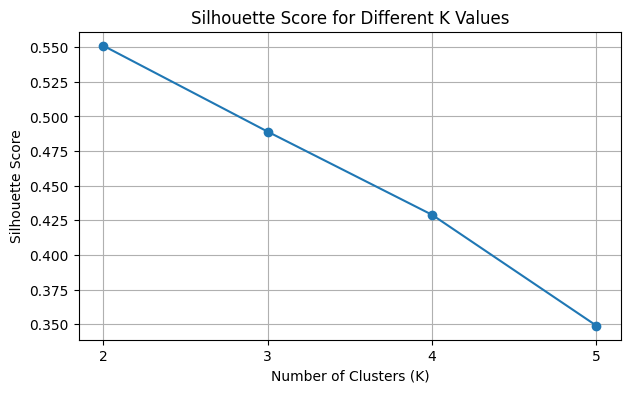

Clustering completed successfully!
Generated: Bengaluru_Traffic_Cluster_Results.csv


In [1]:

# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 2. Load the area-wise analysis file
df = pd.read_csv("Area_Wise_Traffic_Analysis.csv")

# 3. Select the features used for clustering
features = [
    "Avg_Traffic_Volume",
    "Avg_Speed",
    "Avg_Congestion",
    "Avg_Capacity_Utilization",
    "Avg_Incidents"
]

X = df[features].copy()

# 4. Standardise the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Test different numbers of clusters
scores = []

for k in range(2, 6):
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    scores.append({"K": k, "Silhouette_Score": round(score, 3)})

score_df = pd.DataFrame(scores)
print("Silhouette scores:")
display(score_df)

# 6. Create the final K-Means model using K=2
kmeans = KMeans(n_clusters=2, random_state=42, n_init=20)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# 7. Identify which cluster has higher average congestion
cluster_congestion = df.groupby("Cluster")["Avg_Congestion"].mean()
high_cluster = cluster_congestion.idxmax()

df["Congestion_Group"] = df["Cluster"].apply(
    lambda x: "Higher Congestion" if x == high_cluster
    else "Lower Congestion"
)

# 8. Display the area-wise cluster assignments
display(
    df[["Area Name", "Cluster", "Congestion_Group"]]
    .sort_values("Cluster")
)

# 9. Display the cluster profiles
cluster_profile = df.groupby("Congestion_Group")[features].mean().round(2)
print("Cluster profiles:")
display(cluster_profile)

# 10. Plot silhouette scores
plt.figure(figsize=(7, 4))
plt.plot(score_df["K"], score_df["Silhouette_Score"], marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(range(2, 6))
plt.grid(True)
plt.show()

# 11. Save the cluster results
df.to_csv("Bengaluru_Traffic_Cluster_Results.csv", index=False)

print("Clustering completed successfully!")
print("Generated: Bengaluru_Traffic_Cluster_Results.csv")
